#### Import Dependencies

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#### Read in dataset

In [2]:
# set directory path
data_dir = Path("data/electric_school_bus_adoption_dataset_v10_2026-06jun")
data_file = data_dir / "ESB_adoption_dataset_v10_update_june_2026.xlsx"

# read in files
df = pd.read_excel(data_file)


#### Inspect all sheets and create dataframes

In [3]:
# excel sheet dictionary to name dataframes
sheet_map = {
    "1. District-level data": "districts",
    "2. Bus-level data": "buses",
    "3. State-level data": "states",
    "4. Utilities": "utilities",
    "5. Counties": "counties",
    "6. Congressional districts": "congress",
}

# read sheets
all_sheets = pd.read_excel(data_file, sheet_name=None)

# loop through sheets and create df
for sheet_name, name in sheet_map.items():
    globals()[f"df_{name}"] = all_sheets[sheet_name]
    print(f"Created df_{name} with shape {globals()[f'df_{name}'].shape}")

Created df_districts with shape (19520, 92)
Created df_buses with shape (14155, 40)
Created df_states with shape (57, 20)
Created df_utilities with shape (19186, 41)
Created df_counties with shape (25407, 6)
Created df_congress with shape (22695, 7)


#### Create master bus dataframe merging on LEA ID (local education agency ID)

In [4]:
df_master_buses = (
    df_buses.merge(
        df_districts, on="1c. LEA ID", how="left", suffixes=("", "_district")
    )
    .merge(df_utilities, on="1c. LEA ID", how="left", suffixes=("", "_utility"))
    .merge(df_states, on="1a. State", how="left", suffixes=("", "_state"))
)
print(
    f"Master Bus Table: {df_master_buses.shape[0]} buses, {df_master_buses.shape[1]} columns"
)
df_master_buses.head()

Master Bus Table: 14155 buses, 190 columns


,1a. State,1b. LEA or entity name,1c. LEA ID,1f. City,2c. Fleet operator 1,2c. Fleet operator 2,3a. Number of ESBs committed,3n. Current status of bus,3o. Batch,3p. Quarter awarded,...,3j. Average purchase price of Type C ESB (2022-2025),3k. Number of type c ESBs with purchase price data,3l. Minimum purchase price of a Type C ESB (2022-2025),3m. Maximum purchase price of a Type C ESB (2022-2025),8a. Approximate total number of students riding ESBs,"8b. Number of persons, mode to school: school bus","8c. Percent of persons, mode to school: school bus",8d. Pupil transportation requirement?,8e. Details,8f. Pupil transportation funding method
0,CALIFORNIA,Menlo School,80916,Atherton,Zum,NaN,1,Operating,1.0,2020 Q1,...,431297.256400,25.0,270647.74,472899.39,57819.82234,546000.0,0.089,No,NaN,Block grant
1,CALIFORNIA,The Nueva Middle School,89169,Hillsborough,Zum,NaN,1,Operating,1.0,2020 Q1,...,431297.256400,25.0,270647.74,472899.39,57819.82234,546000.0,0.089,No,NaN,Block grant
2,ALABAMA,Albertville City,100005,Albertville,NaN,NaN,19,Operating,1.0,2022 Q4,...,373142.155862,29.0,369610.23,375000.00,1090.20643,249000.0,0.363,NaN,NaN,NaN
3,ALABAMA,Albertville City,100005,Albertville,NaN,NaN,19,Operating,1.0,2022 Q4,...,373142.155862,29.0,369610.23,375000.00,1090.20643,249000.0,0.363,NaN,NaN,NaN
4,ALABAMA,Albertville City,100005,Albertville,NaN,NaN,19,Operating,1.0,2022 Q4,...,373142.155862,29.0,369610.23,375000.00,1090.20643,249000.0,0.363,NaN,NaN,NaN


#### Create district-level master dataframe

In [5]:
df_master_districts = df_districts.merge(
    df_utilities, on="1c. LEA ID", how="left", suffixes=("", "_utility")
).merge(df_states, on="1a. State", how="left", suffixes=("", "_state"))
print(
    f"Master District Table: {df_master_districts.shape[0]} districts, {df_master_districts.shape[1]} columns"
)
df_master_districts.head()

Master District Table: 19520 districts, 151 columns


,0a. Has Committed ESBs?,1a. State,1b. Local Education Agency (LEA) or entity name,1c. LEA ID,1d. Street address 1,1e. Street address 2,1f. City,1g. State,1h. ZIP code,1i. Website,...,3j. Average purchase price of Type C ESB (2022-2025),3k. Number of type c ESBs with purchase price data,3l. Minimum purchase price of a Type C ESB (2022-2025),3m. Maximum purchase price of a Type C ESB (2022-2025),8a. Approximate total number of students riding ESBs,"8b. Number of persons, mode to school: school bus","8c. Percent of persons, mode to school: school bus",8d. Pupil transportation requirement?,8e. Details,8f. Pupil transportation funding method
0,yes,ILLINOIS,Cook-Illinois Corp,17COOKI,NaN,NaN,NaN,IL,NaN,cookillinois.com,...,366359.790549,91.0,327287.32,400385.0,7516.265349,754000.0,0.371,Yes,"All districts except old type-unit, community ...",Partial Reimbursement of Allowable Costs
1,yes,MISSISSIPPI,ABERDEEN SCHOOL DIST,2800360,1100 W Commerce,NaN,Aberdeen,MS,39730.0,http://www.asdms.us,...,375148.296296,54.0,375000.00,375728.0,5298.138680,240000.0,0.502,NaN,NaN,NaN
2,no,ALABAMA,Alabama Youth Services,100002,1000 Industrial School Road,NaN,Mt Meigs,AL,36057.0,http://www.dys.alabama.gov/school-district.html,...,373142.155862,29.0,369610.23,375000.0,1090.206430,249000.0,0.363,NaN,NaN,NaN
3,yes,NEVADA,CLARK COUNTY SCHOOL DISTRICT,3200060,5100 WEST SAHARA AVE.,NaN,LAS VEGAS,NV,89146.0,NaN,...,NaN,NaN,NaN,NaN,1980.622222,159000.0,0.429,No,NaN,Block Grant
4,no,GEORGIA,Gwinnett County,1302550,52 Gwinnett Dr,NaN,Lawrenceville,GA,30045.0,NaN,...,375384.615385,117.0,375000.00,390000.0,6267.775039,847000.0,0.497,NaN,NaN,NaN


#### Print out column names from both master dataframes

In [6]:
df_master_buses.columns.tolist()

['1a. State',
 '1b. LEA or entity name',
 '1c. LEA ID',
 '1f. City',
 '2c. Fleet operator 1',
 '2c. Fleet operator 2',
 '3a. Number of ESBs committed ',
 '3n. Current status of bus',
 '3o. Batch',
 '3p. Quarter awarded',
 '3q. Quarter ordered',
 '3r. Quarter delivered',
 '3s. Quarter first operating',
 '3t. Bus OEM',
 '3u. Electric powertrain manufacturer',
 '3v. Model',
 '3w. Type',
 '3x. Dealer',
 '3y. Multiple funding sources used?',
 '3z. Funding source 1',
 '3aa. Agency administering funds 1',
 '3z. Funding source 2',
 '3aa. Agency administering funds 2',
 '3z. Funding source 3',
 '3aa. Agency administering funds 3',
 '3z. Funding source 4',
 '3aa. Agency administering funds 4',
 '3ab. Dollar amount toward bus',
 '3ac. Charging company',
 '3ad. Charging funding source',
 '3ae. Dollar amount toward charger',
 '3af. Notes 1',
 '3af. Notes 2',
 '7b. Source 1',
 '7b. Source 2',
 '7b. Source 3',
 '7b. Source 4',
 '7b. Source 5',
 '7b. Source 6',
 '7b. Source 7',
 '0a. Has Committed ESB

In [7]:
df_master_districts.columns.tolist()

['0a. Has Committed ESBs?',
 '1a. State',
 '1b. Local Education Agency (LEA) or entity name',
 '1c. LEA ID',
 '1d. Street address 1',
 '1e. Street address 2',
 '1f. City',
 '1g. State',
 '1h. ZIP code',
 '1i. Website',
 '1j. Has LEA ID?',
 '1k. LEA type (number)',
 '1l. LEA type (name)',
 '1m. Supervisory union LEA ID',
 '1n. Locale (full number)',
 '1o. Locale broad type (number)',
 '1p. Locale broad type (name)',
 '1q. Census Region',
 '1r. Census Division',
 '1s. Latitude',
 '1t. Longitude ',
 '2a. Total number of buses',
 '2b. Contractor used for some or all of buses?',
 '3a. Number of ESBs committed ',
 '3b. Number of delivered or operating ESBs',
 '3c. Number of ESBs awarded',
 '3d. Number of ESBs ordered',
 '3e. Number of ESBs delivered',
 '3f. Number of ESBs operating',
 '3g. Number of batches',
 '3h. Size of batch 1',
 '3h. Size of batch 2',
 '3h. Size of batch 3',
 '3h. Size of batch 4',
 '3h. Size of batch 5',
 '3i. Percent of fleet that is electric',
 '3j. Government agency

#### Explore Districts

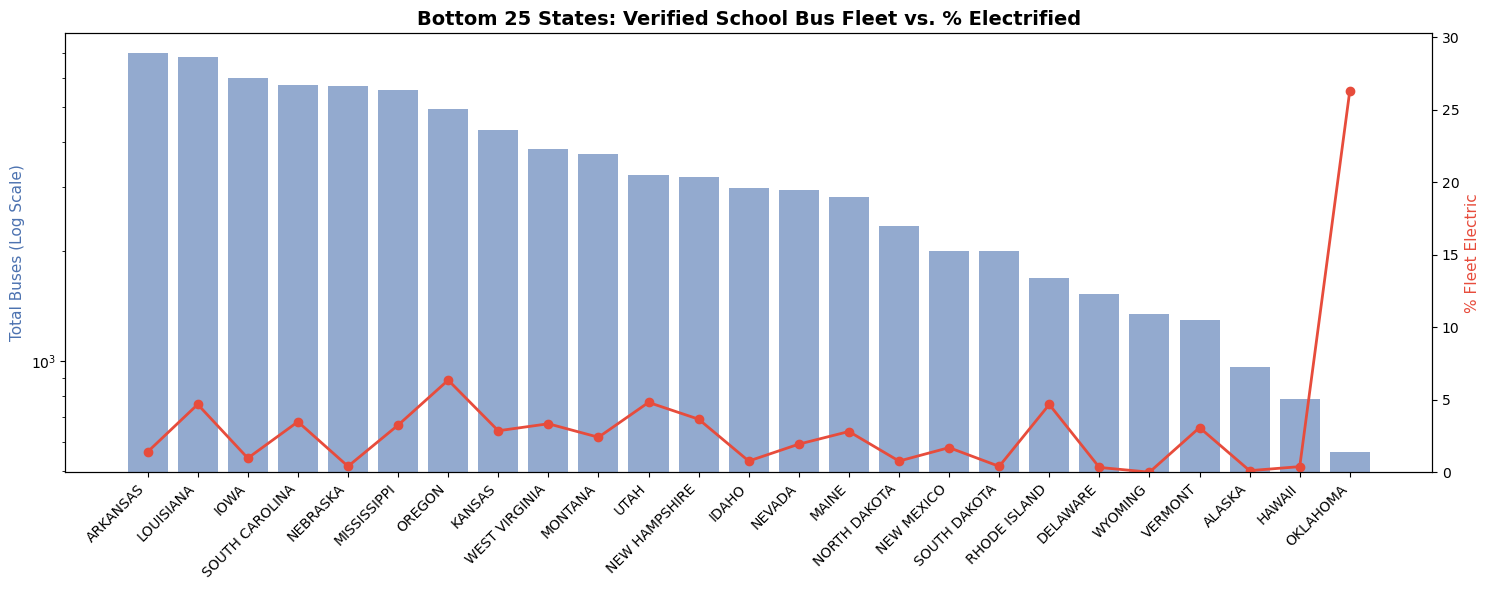

In [32]:
# dictionary to rename columns
column_mapping = {
    "1a. State": "State",
    "2a. Total number of school buses (SBF 2022-23)": "Total_Buses",
    "3a. Number of committed ESBs": "Electric_Buses",
}

# map column names to keys
state_clean = df_states[list(column_mapping.keys())].rename(
    columns=column_mapping
)


# coerce numeric values
state_clean["Total_Buses"] = pd.to_numeric(
    state_clean["Total_Buses"], errors="coerce"
)
state_clean["Electric_Buses"] = pd.to_numeric(
    state_clean["Electric_Buses"], errors="coerce"
)
state_clean = state_clean.dropna().query('State != "UNITED STATES"')


# calculate % electric
state_clean["pct_electric"] = (
    state_clean["Electric_Buses"] / state_clean["Total_Buses"]
) * 100

state_clean = state_clean.sort_values(by="Total_Buses", ascending=False).tail(25)

# Plot
fig, ax1 = plt.subplots(figsize=(15, 6))

bars = ax1.bar(
    state_clean["State"],
    state_clean["Total_Buses"],
    color="#4c72b0",
    alpha=0.6,
    label="Total Buses",
)

ax1.set_yscale("log")
ax1.set_ylabel("Total Buses (Log Scale)", color="#4c72b0", fontsize=11)
ax1.set_xticks(range(len(state_clean)))
ax1.set_xticklabels(state_clean["State"], rotation=45, ha="right")

ax2 = ax1.twinx()
lines = ax2.plot(
    state_clean["State"],
    state_clean["pct_electric"],
    color="#e74c3c",
    marker="o",
    linewidth=2,
    label="% Electric",
)

ax2.set_ylabel("% Fleet Electric", color="#e74c3c", fontsize=11)
ax2.set_ylim(0, state_clean["pct_electric"].max() * 1.15)

plt.title(
    "Bottom 25 States: Verified School Bus Fleet vs. % Electrified",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


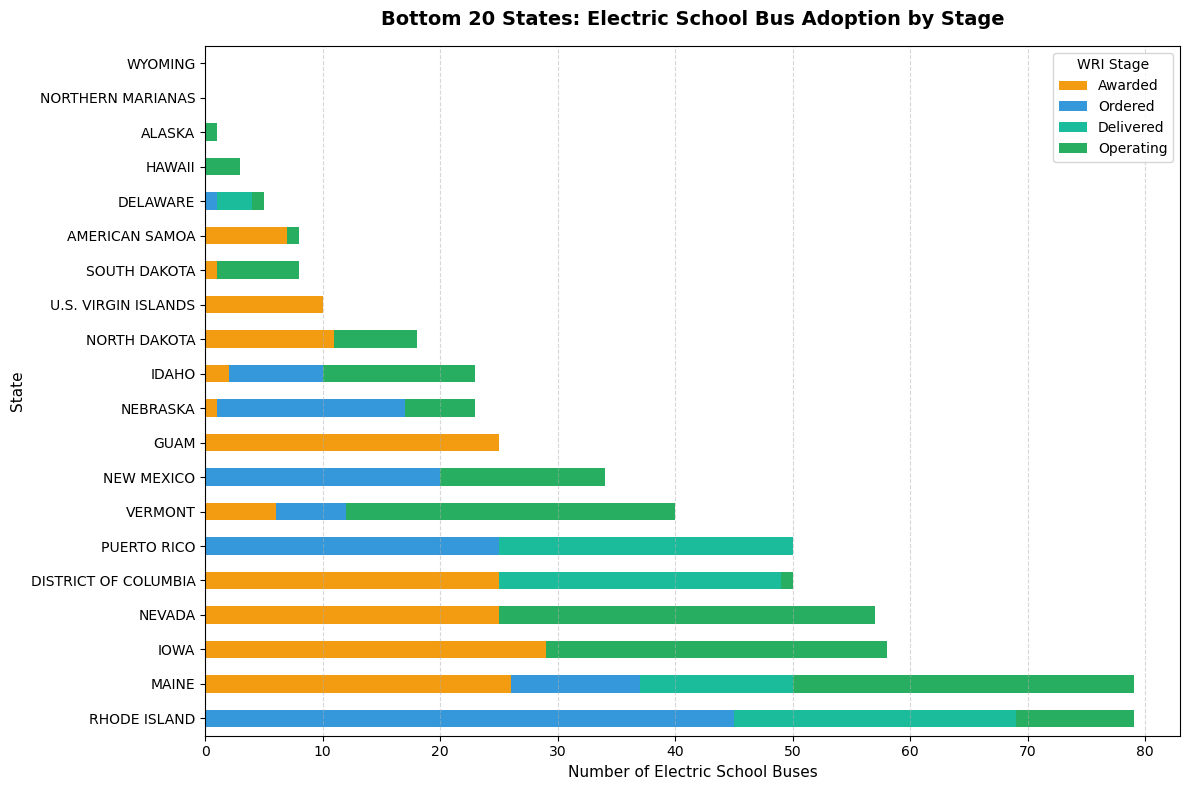

In [64]:
# aggregate the four WRI scenarios by state

stages_by_state = (
    df_districts.groupby("1a. State")
    .agg(
        Awarded=("3c. Number of ESBs awarded", "sum"),
        Ordered=("3d. Number of ESBs ordered", "sum"),
        Delivered=("3e. Number of ESBs delivered", "sum"),
        Operating=("3f. Number of ESBs operating", "sum"),
    )
    .reset_index()
    .rename(columns={"1a. State": "State"})
)

stages_by_state = stages_by_state.dropna().query('State != "UNITED STATES"')

stages_by_state["Total"] = stages_by_state[["Awarded", "Ordered", "Delivered", "Operating"]].sum(axis=1)
bottom_states = (
    stages_by_state.sort_values(by="Total", ascending=False).tail(20).set_index("State")
)

# plot horizontal stacked bar chart
colors = [
    "#f39c12",
    "#3498db",
    "#1abc9c",
    "#27ae60",
]  # Amber (Awarded); Blue (Ordered); Teal (Delivered); Green (Operating)
ax = bottom_states[["Awarded", "Ordered", "Delivered", "Operating"]].plot(
    kind="barh", stacked=True, figsize=(12, 8), color=colors, edgecolor="none"
)

plt.title(
    "Bottom 20 States: Electric School Bus Adoption by Stage",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Number of Electric School Buses", fontsize=11)
plt.ylabel("State", fontsize=11)
plt.legend(title="WRI Stage", frameon=True)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [75]:
# standard cleanup
df_districts.columns = df_districts.columns.str.strip()
df_utilities.columns = df_utilities.columns.str.strip()

# column name dictionary
district_cols = {
    "1a. State": "State",
    "1c. LEA ID": "LEA_ID",
    "2a. Total number of buses": "Total_Buses",
    "3a. Number of ESBs committed": "Electric_Buses",
}

# map names
df_dist = df_districts.rename(columns=district_cols)

# aggregate adoption
state_rates = (
    df_dist.groupby("State")[["Total_Buses", "Electric_Buses"]]
    .sum()
    .reset_index()
)

state_rates["pct_electric"] = (
    state_rates["Electric_Buses"] / state_rates["Total_Buses"]
) * 100

bottom_20_states = (
    state_rates[state_rates["Total_Buses"] > 0]
    .sort_values(by="pct_electric", ascending=True)
    .head(20)["State"]
    .tolist()
)

print("Bottom 20 States:", bottom_20_states)


Bottom 20 States: ['WYOMING', 'ALASKA', 'DELAWARE', 'HAWAII', 'IDAHO', 'NORTH DAKOTA', 'OHIO', 'TEXAS', 'INDIANA', 'TENNESSEE', 'KENTUCKY', 'ALABAMA', 'IOWA', 'ARKANSAS', 'NEW MEXICO', 'GEORGIA', 'WISCONSIN', 'NEVADA', 'MISSOURI', 'NORTH CAROLINA']


#### Utility Ownership Model of ESBs for the bottom 20 states

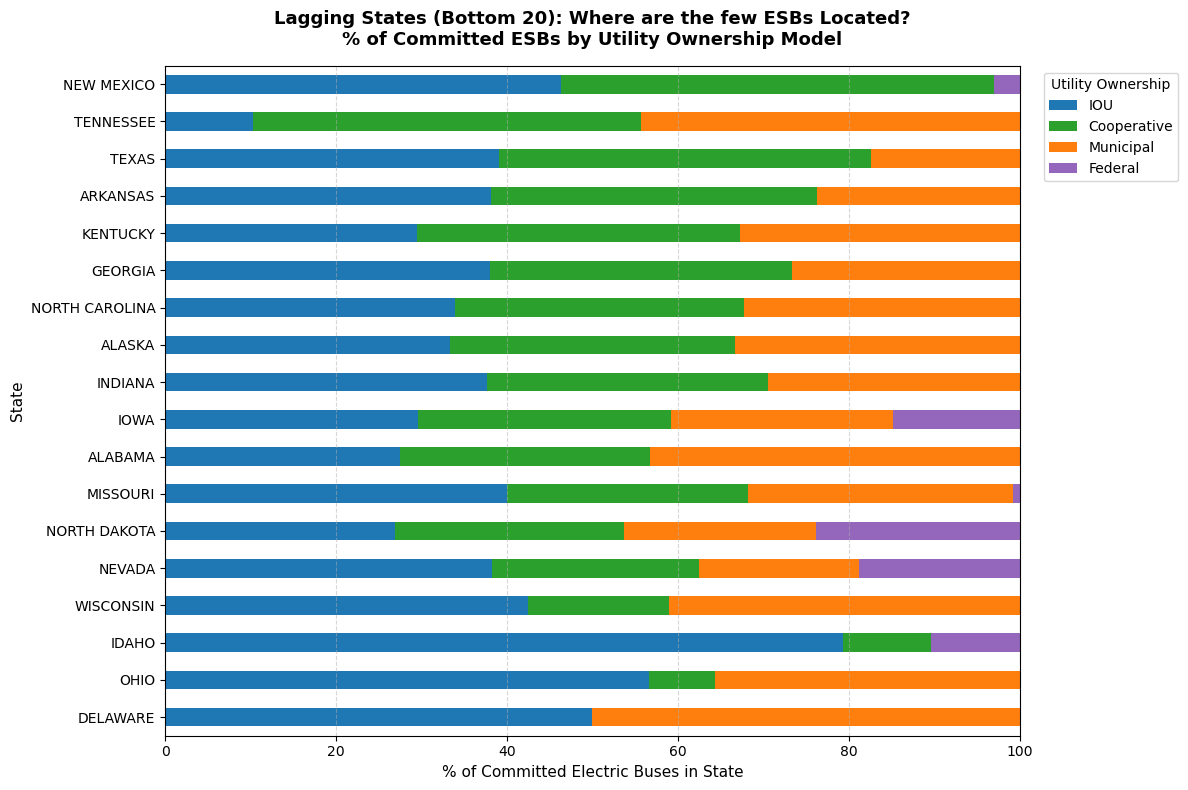

In [86]:
# merge datasets only looking at bottom 20 states
dist_esb = df_districts[["1c. LEA ID", "1a. State", "3a. Number of ESBs committed"]].copy()
dist_esb = dist_esb[dist_esb["1a. State"].isin(bottom_20_states)]

util_types = {
    "9d. Investor ownership": "IOU",
    "9b. Cooperative ownership": "Cooperative",
    "9e. Municipal ownership": "Municipal",
    "9c. Federal ownership": "Federal",
}

merged = dist_esb.merge(
    df_utilities[["1c. LEA ID"] + list(util_types.keys())],
    on="1c. LEA ID",
    how="inner",
)

# weighted by ESBs committed 
for raw_col, label in util_types.items():
    is_served = (merged[raw_col].astype(str).str.lower() == "yes").astype(int)
    merged[label] = is_served * merged["3a. Number of ESBs committed"]

# 5. Aggregate ESBs by utility type across the bottom 20 states
type_labels = list(util_types.values())
state_esb_util = (
    merged.groupby("1a. State")[type_labels].sum()
)

# only keep states with at least 1 ESB
state_esb_util = state_esb_util[state_esb_util.sum(axis=1) > 0]
state_esb_pct = state_esb_util.div(state_esb_util.sum(axis=1), axis=0) * 100


state_esb_pct = state_esb_pct.sort_values(by="Cooperative", ascending=True)


colors = [
    "#1f77b4",  # Blue: IOU
    "#2ca02c",  # Green: Coop
    "#ff7f0e",  # Orange: Muni
    "#9467bd",  # Purple: Federal
]

ax = state_esb_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    color=colors,
    edgecolor="none"
)

plt.title(
    "Lagging States (Bottom 20): Where are the few ESBs Located?\n"
    "% of Committed ESBs by Utility Ownership Model",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("% of Committed Electric Buses in State", fontsize=11)
plt.ylabel("State", fontsize=11)
plt.xlim(0, 100)
plt.legend(title="Utility Ownership", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [105]:
df_districts.columns = df_districts.columns.str.strip()
df_utilities.columns = df_utilities.columns.str.strip()

top_candidates = df_districts.copy()

col_map = {
    "1a. State": "State",
    "1b. Local Education Agency (LEA) or entity name": "District_Name",
    "1c. LEA ID": "LEA_ID",
    "1p. Locale broad type (name)": "Locale",
    "2a. Total number of buses": "Fleet_Size",
    "3a. Number of ESBs committed": "Electric_Buses",
    "4e. Percentage of students in district eligible for free or reduced price lunch": "Free_Lunch_Pct", # low income
    "5p. EPA 2023 Clean School Bus Grant & Rebate Programs prioritized school district?": "EPA_Prioritized", # EPA prioritized
    "6e. Applied for ESB funding but not awarded": "Denied_Funding",
}

top_candidates = df_districts[list(col_map.keys())].rename(columns=col_map)

# coerce to numeric and fill empty 
top_candidates["Fleet_Size"] = pd.to_numeric(top_candidates["Fleet_Size"], errors="coerce").fillna(0)
top_candidates["Electric_Buses"] = pd.to_numeric(top_candidates["Electric_Buses"], errors="coerce").fillna(0)
top_candidates["Free_Lunch_Pct"] = (pd.to_numeric(top_candidates["Free_Lunch_Pct"], errors="coerce").fillna(0) * 100)

target_districts = top_candidates[
    (top_candidates["EPA_Prioritized"] == "Yes")
    & (top_candidates["Denied_Funding"].notna()) # verify entry denied application
    & (top_candidates["Denied_Funding"].str.strip() != "") # avoid double counting
    & (top_candidates["Electric_Buses"] == 0)
    & (top_candidates["Fleet_Size"] >= 30)
].copy()

# look up table 

util_map = (
    df_utilities[["1c. LEA ID", "9a. Utility name 1"]]
    .rename(
        columns={"1c. LEA ID": "LEA_ID", "9a. Utility name 1": "Primary_Utility"}
    )
    .dropna(subset=["LEA_ID"])
)


target_districts = target_districts.merge(util_map, on="LEA_ID", how="left")

target_districts["Primary_Utility"] = target_districts[
    "Primary_Utility"
].fillna("Local Utility / Municipal") # if utility is left blank, add default value

target_districts = target_districts.sort_values(
    by="Fleet_Size", ascending=False
)
top_candidates = target_districts[
    [
        "District_Name",
        "State",
        "Fleet_Size",
        "Locale",
        "Free_Lunch_Pct",
        "Primary_Utility",
        "Denied_Funding",
    ]
].head(30)

top_candidates

,District_Name,State,Fleet_Size,Locale,Free_Lunch_Pct,Primary_Utility,Denied_Funding
0,Columbus City Schools District,OHIO,905.0,Urban,0.000000,OHIO POWER CO,2022 CSBP rebate
1,Mobile County,ALABAMA,765.0,Urban,69.449201,ALABAMA POWER CO,2022 CSBP rebate
2,POLK,FLORIDA,654.0,Suburban,54.407711,"DUKE ENERGY FLORIDA, LLC",2022 CSBP rebate
3,ALDINE ISD,TEXAS,582.0,Suburban,91.585378,ENTERGY TEXAS INC.,2022 CSBP rebate
4,EL PASO ISD,TEXAS,372.0,Urban,75.844976,"RIO GRANDE ELECTRIC COOP, INC",2022 CSBP rebate
5,SPRING ISD,TEXAS,345.0,Suburban,84.235211,ENTERGY TEXAS INC.,2022 CSBP rebate
6,Newport News City Public Schools,VIRGINIA,340.0,Urban,87.965022,VIRGINIA ELECTRIC & POWER CO,2022 CSBP rebate
7,Norfolk City Public Schools,VIRGINIA,321.0,Urban,95.495495,VIRGINIA ELECTRIC & POWER CO,2022 CSBP rebate; 2023 CSBP grant
8,LA JOYA ISD,TEXAS,305.0,Suburban,93.638123,AEP TEXAS CENTRAL COMPANY,2022 CSBP rebate
9,Cleveland Municipal,OHIO,290.0,Urban,0.000000,CLEVELAND ELECTRIC ILLUM CO,2022 CSBP rebate


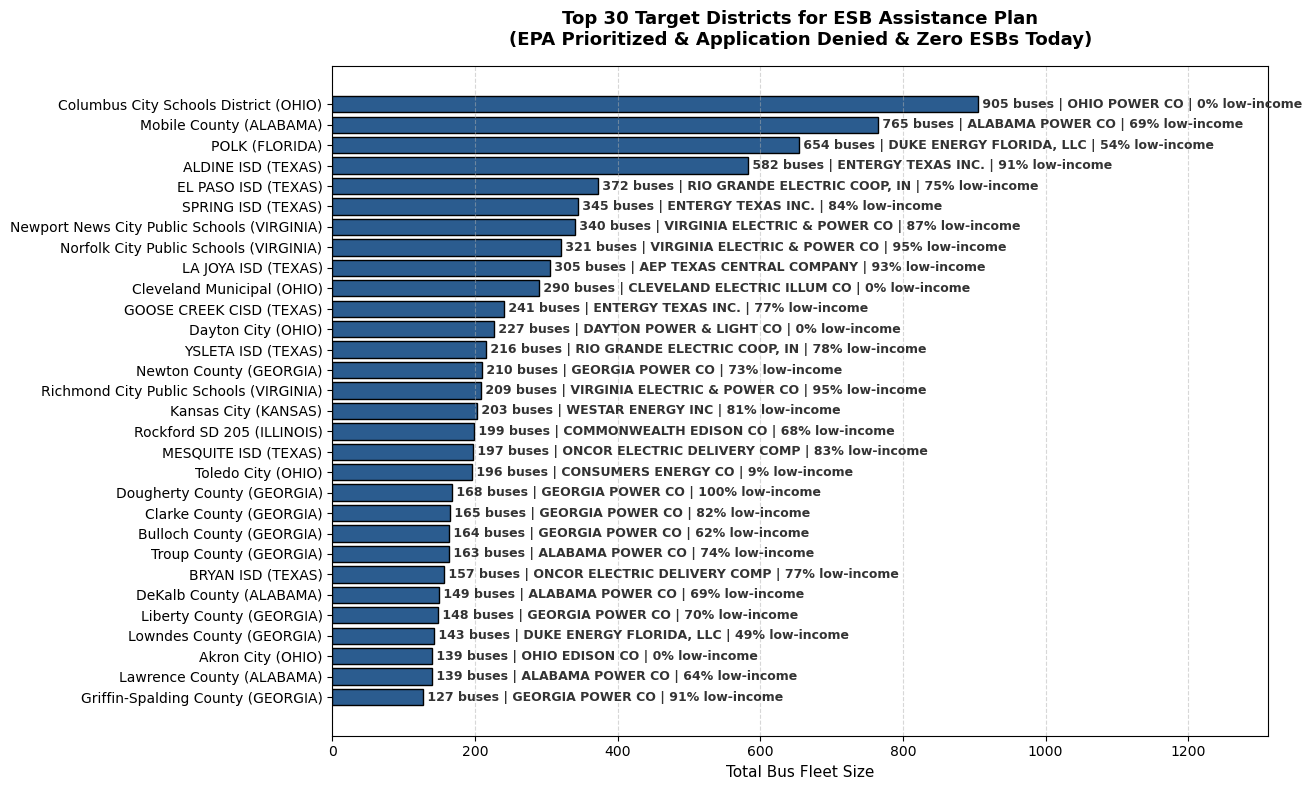

In [108]:
top_districts = target_districts.head(30).sort_values(by="Fleet_Size", ascending=True)

fig, ax = plt.subplots(figsize=(13, 8))

# horizontal bar
bars = ax.barh(
    top_districts["District_Name"] + " (" + top_districts["State"] + ")",
    top_districts["Fleet_Size"],
    color="#2b5c8f",
    edgecolor="black",
)

# bar annotations
for bar, (_, row) in zip(bars, top_districts.iterrows()):
    w = bar.get_width()
    util = str(row["Primary_Utility"])[:28]
    lunch = int(row["Free_Lunch_Pct"])

    ax.annotate(
        f" {int(w)} buses | {util} | {lunch}% low-income",
        (w, bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#333333",
    )

ax.set_xlabel("Total Bus Fleet Size", fontsize=11)
ax.set_title(
    "Top 30 Target Districts for ESB Assistance Plan\n"
    "(EPA Prioritized & Application Denied & Zero ESBs Today)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_xlim(0, top_districts["Fleet_Size"].max() * 1.45)
plt.tight_layout()
plt.show()
